<a href="https://colab.research.google.com/github/Cristhian-Victoria/gestortareasJJC/blob/main/Copia_de_Te_damos_la_bienvenida_a_Colaboratory.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Nueva sección

✅ Todas las bibliotecas importadas correctamente.
   NetworkX versión: 3.6.1
   Pandas versión:   2.2.2
✅ Dataset generado exitosamente.
   Total de registros: 1000
   Columnas: ['fecha', 'cuenta_origen', 'cuenta_destino', 'monto', 'tipo_transaccion']

📋 Primeras 5 filas del dataset:
        fecha   cuenta_origen    cuenta_destino     monto tipo_transaccion
0  2024-04-24          Bancos              Caja  37103.37           compra
1  2024-02-14      Inventario            Bancos  33867.30             pago
2  2024-04-21       Impuestos  Gastos_Generales   1685.96            venta
3  2024-04-11     Proveedores         Impuestos  30140.73             pago
4  2024-05-22  Capital_Social  Gastos_Generales  11099.99             pago

📊 Resumen estadístico de montos:
count     1000.000000
mean     25835.103960
std      14388.021119
min        332.990000
25%      13294.027500
50%      25479.340000
75%      38647.282500
max      49995.400000
Name: monto, dtype: float64
✅ Grafo dirigido construido

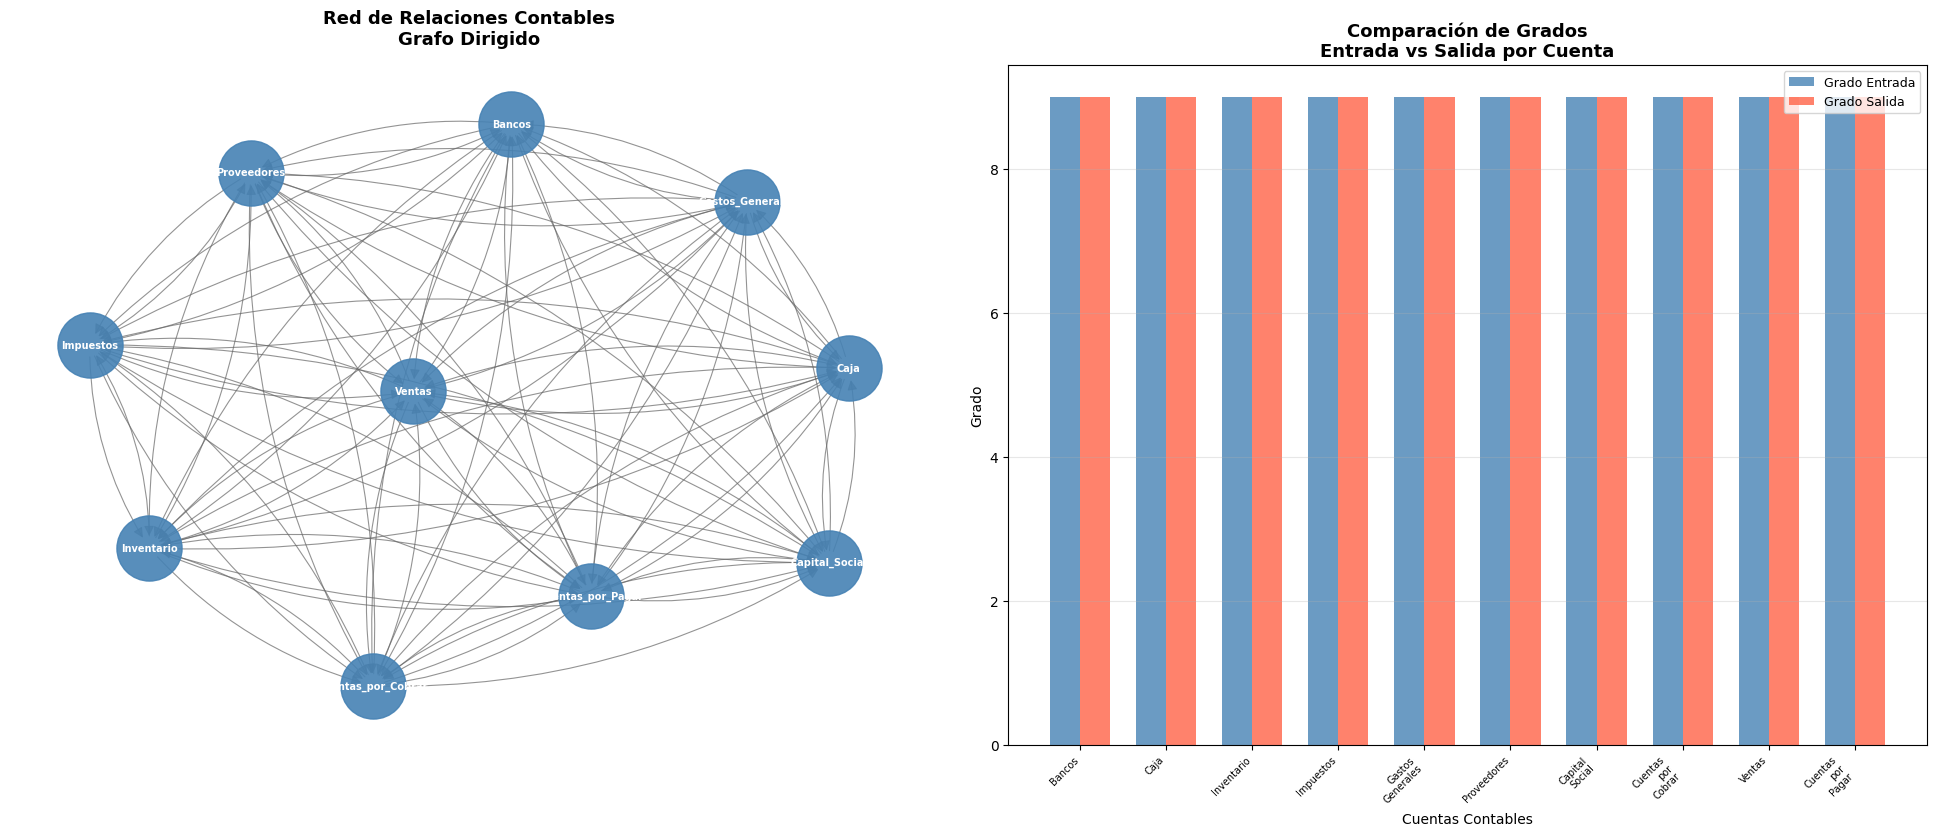

✅ Grafo visualizado y guardado como 'grafo_relaciones_contables.png'
     INFORME INTERPRETATIVO — RED DE RELACIONES CONTABLES

📌 CUENTA CON MAYOR GRADO DE ENTRADA: Bancos
   → Grado de entrada: 9
   → Interpretación: Es el principal DESTINO de transacciones.
     La mayoría de las cuentas envían recursos hacia ella.

📌 CUENTA CON MAYOR GRADO DE SALIDA: Bancos
   → Grado de salida: 9
   → Interpretación: Es la principal FUENTE de transacciones.
     Origina la mayor cantidad de movimientos financieros.

📌 CUENTA MÁS ACTIVA (mayor grado total): Bancos
   → Grado total: 18
   → Interpretación: Es el nodo más conectado del grafo.

📊 RESUMEN DEL GRAFO:
   • Total de cuentas (nodos):          10
   • Total de relaciones (aristas):      90
   • ¿Grafo dirigido?:                   Sí (DiGraph)
   • Total de transacciones analizadas:  1000
   • Monto total transado:              $25,835,103.96
   • Monto promedio por transacción:    $25,835.10

✅ Análisis completado exitosamente.


In [ ]:
# ============================================================
# RED DE RELACIONES CONTABLES MEDIANTE GRAFOS DIRIGIDOS
# Proyecto: Estructuras de Datos — Google Colaboratory
# ============================================================

# ── CELDA 1: Instalación e importación de bibliotecas ──────
# Estas bibliotecas deben estar disponibles en Colab
# (pandas, networkx y matplotlib vienen preinstaladas)
# numpy se usa para la matriz de adyacencia

import pandas as pd          # Manejo del dataset de transacciones
import networkx as nx         # Creación y análisis del grafo dirigido
import matplotlib.pyplot as plt  # Visualización del grafo
import numpy as np            # Operaciones matriciales
import random                 # Generación de datos aleatorios
from datetime import date, timedelta  # Manejo de fechas

print("✅ Todas las bibliotecas importadas correctamente.")
print(f"   NetworkX versión: {nx.__version__}")
print(f"   Pandas versión:   {pd.__version__}")


# ── CELDA 2: Generación del Dataset ────────────────────────
# DATOS DE ENTRADA:
#   - Lista de cuentas contables (10 cuentas)
#   - Rango de fechas: año 2024
#   - Rango de montos: $100 a $50,000
# RESULTADO: DataFrame con 1,000 transacciones financieras
# COLUMNAS: fecha, cuenta_origen, cuenta_destino, monto, tipo_transaccion

random.seed(42)  # Semilla para resultados reproducibles

# Las 10 cuentas contables del sistema
cuentas = [
    'Caja', 'Bancos', 'Inventario', 'Proveedores',
    'Cuentas_por_Cobrar', 'Cuentas_por_Pagar',
    'Gastos_Generales', 'Ventas', 'Capital_Social', 'Impuestos'
]

# Tipos de transacciones financieras
tipos = ['venta', 'compra', 'gasto', 'transferencia', 'pago']

# Fecha inicial para las transacciones
fecha_inicio = date(2024, 1, 1)

registros = []
for i in range(1000):
    # Selección aleatoria de cuenta origen
    origen = random.choice(cuentas)
    # Cuenta destino distinta al origen
    destino = random.choice([c for c in cuentas if c != origen])
    # Monto aleatorio entre $100 y $50,000
    monto = round(random.uniform(100, 50000), 2)
    # Tipo de transacción
    tipo = random.choice(tipos)
    # Fecha aleatoria dentro del año 2024
    dias_extra = random.randint(0, 364)
    fecha = fecha_inicio + timedelta(days=dias_extra)

    registros.append([str(fecha), origen, destino, monto, tipo])

# Crear el DataFrame
df = pd.DataFrame(registros, columns=[
    'fecha', 'cuenta_origen', 'cuenta_destino', 'monto', 'tipo_transaccion'
])

print("✅ Dataset generado exitosamente.")
print(f"   Total de registros: {len(df)}")
print(f"   Columnas: {list(df.columns)}")
print("\n📋 Primeras 5 filas del dataset:")
print(df.head())
print("\n📊 Resumen estadístico de montos:")
print(df['monto'].describe())


# ── CELDA 3: Construcción del Grafo Dirigido ───────────────
# FUNCIÓN: nx.from_pandas_edgelist()
# DATOS DE ENTRADA:
#   - df: DataFrame con las transacciones
#   - source: columna 'cuenta_origen' → define el nodo origen de cada arista
#   - target: columna 'cuenta_destino' → define el nodo destino de cada arista
#   - edge_attr: columna 'monto' → peso de cada arista (valor de la transacción)
#   - create_using: nx.DiGraph() → crea un grafo DIRIGIDO (las aristas tienen dirección)
# RESULTADO: Objeto DiGraph con 10 nodos y múltiples aristas dirigidas

G = nx.from_pandas_edgelist(
    df,
    source='cuenta_origen',       # Nodo de partida
    target='cuenta_destino',      # Nodo de llegada
    edge_attr='monto',            # Peso de la relación
    create_using=nx.DiGraph()     # Tipo: Grafo Dirigido
)

print("✅ Grafo dirigido construido exitosamente.")
print(f"   Número de nodos (cuentas): {G.number_of_nodes()}")
print(f"   Número de aristas (relaciones): {G.number_of_edges()}")
print(f"\n   Nodos del grafo: {list(G.nodes())}")
print(f"\n   ¿Es dirigido? {nx.is_directed(G)}")


# ── CELDA 4: Cálculo de Grados de Entrada y Salida ─────────
# FUNCIÓN: G.in_degree()
#   - Calcula cuántas aristas LLEGAN a cada nodo
#   - Resultado: número de cuentas que realizan transacciones HACIA esta cuenta
#   - Grado de entrada alto → la cuenta recibe muchos recursos
#
# FUNCIÓN: G.out_degree()
#   - Calcula cuántas aristas SALEN de cada nodo
#   - Resultado: número de cuentas hacia las que esta cuenta realiza transacciones
#   - Grado de salida alto → la cuenta origina muchos movimientos financieros

# in_degree(): recibe el grafo G, devuelve diccionario {cuenta: grado_entrada}
entrada = dict(G.in_degree())

# out_degree(): recibe el grafo G, devuelve diccionario {cuenta: grado_salida}
salida = dict(G.out_degree())

# Construir tabla de grados
grados_df = pd.DataFrame({
    'Cuenta': list(entrada.keys()),
    'Grado_Entrada': list(entrada.values()),
    'Grado_Salida': list(salida.values()),
    'Grado_Total': [entrada[c] + salida[c] for c in entrada]
}).sort_values('Grado_Total', ascending=False).reset_index(drop=True)

print("✅ Grados calculados exitosamente.")
print("\n📊 TABLA DE GRADOS POR CUENTA CONTABLE:")
print("=" * 60)
print(grados_df.to_string(index=False))
print("=" * 60)
print(f"\n🔝 Cuenta con mayor grado de ENTRADA: {grados_df.loc[grados_df['Grado_Entrada'].idxmax(), 'Cuenta']}")
print(f"🔝 Cuenta con mayor grado de SALIDA:  {grados_df.loc[grados_df['Grado_Salida'].idxmax(), 'Cuenta']}")


# ── CELDA 5: Generación de la Matriz de Adyacencia ─────────
# FUNCIÓN: nx.to_numpy_array()
# DATOS DE ENTRADA:
#   - G: el grafo dirigido
#   - nodelist: orden de los nodos en la matriz
# RESULTADO: Matriz 10x10 donde A[i][j] = 1 si existe arista de nodo_i a nodo_j
# La matriz NO es simétrica porque el grafo es dirigido

nodos_ordenados = sorted(list(G.nodes()))
A = nx.to_numpy_array(G, nodelist=nodos_ordenados)
adj_df = pd.DataFrame(A.astype(int), index=nodos_ordenados, columns=nodos_ordenados)

print("✅ Matriz de adyacencia generada.")
print("\n📐 MATRIZ DE ADYACENCIA (10x10):")
print("   (1 = existe relación directa entre cuentas, 0 = no existe)")
print()
print(adj_df)
print(f"\n   Nota: La matriz es {'simétrica' if (A == A.T).all() else 'ASIMÉTRICA'} → confirma que el grafo es dirigido.")


# ── CELDA 6: Visualización del Grafo ───────────────────────
# DATOS DE ENTRADA: el grafo G construido previamente
# RESULTADO: Imagen del grafo con nodos (cuentas) y aristas dirigidas (transacciones)
#
# Explicación de cada parámetro visual:
#   - Nodos (círculos azules): representan las cuentas contables
#   - Flechas: indican la dirección del flujo financiero
#   - Etiquetas: nombre de cada cuenta contable
#   - spring_layout: algoritmo que posiciona los nodos según sus conexiones

fig, axes = plt.subplots(1, 2, figsize=(20, 9))

# ── Sub-gráfico 1: Grafo principal ─────────────────────────
ax1 = axes[0]
pos = nx.spring_layout(G, seed=42, k=2.5)

# Dibujar nodos
nx.draw_networkx_nodes(G, pos, ax=ax1,
                       node_color='steelblue',
                       node_size=2200,
                       alpha=0.9)

# Dibujar etiquetas de nodos
nx.draw_networkx_labels(G, pos, ax=ax1,
                        font_size=7,
                        font_color='white',
                        font_weight='bold')

# Dibujar aristas con flechas curvas (para mostrar ambas direcciones)
nx.draw_networkx_edges(G, pos, ax=ax1,
                       edge_color='#666666',
                       arrows=True,
                       arrowsize=15,
                       arrowstyle='-|>',
                       connectionstyle='arc3,rad=0.15',
                       width=0.8,
                       alpha=0.7)

ax1.set_title('Red de Relaciones Contables\nGrafo Dirigido', fontsize=13, fontweight='bold', pad=15)
ax1.axis('off')

# ── Sub-gráfico 2: Gráfica de barras de grados ─────────────
ax2 = axes[1]
x = range(len(grados_df))
width = 0.35

bars1 = ax2.bar([i - width/2 for i in x], grados_df['Grado_Entrada'],
                width, label='Grado Entrada', color='steelblue', alpha=0.8)
bars2 = ax2.bar([i + width/2 for i in x], grados_df['Grado_Salida'],
                width, label='Grado Salida', color='tomato', alpha=0.8)

ax2.set_xlabel('Cuentas Contables', fontsize=10)
ax2.set_ylabel('Grado', fontsize=10)
ax2.set_title('Comparación de Grados\nEntrada vs Salida por Cuenta', fontsize=13, fontweight='bold')
ax2.set_xticks(list(x))
ax2.set_xticklabels(
    [c.replace('_', '\n') for c in grados_df['Cuenta']],
    rotation=45, ha='right', fontsize=7
)
ax2.legend(fontsize=9)
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout(pad=3.0)
plt.savefig('grafo_relaciones_contables.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Grafo visualizado y guardado como 'grafo_relaciones_contables.png'")


# ── CELDA 7: Análisis Final e Informe Interpretativo ────────
print("=" * 65)
print("     INFORME INTERPRETATIVO — RED DE RELACIONES CONTABLES")
print("=" * 65)

# Cuenta con más entrada
max_entrada = grados_df.loc[grados_df['Grado_Entrada'].idxmax()]
# Cuenta con más salida
max_salida = grados_df.loc[grados_df['Grado_Salida'].idxmax()]
# Cuenta más activa en total
max_total = grados_df.loc[grados_df['Grado_Total'].idxmax()]

print(f"\n📌 CUENTA CON MAYOR GRADO DE ENTRADA: {max_entrada['Cuenta']}")
print(f"   → Grado de entrada: {max_entrada['Grado_Entrada']}")
print(f"   → Interpretación: Es el principal DESTINO de transacciones.")
print(f"     La mayoría de las cuentas envían recursos hacia ella.")

print(f"\n📌 CUENTA CON MAYOR GRADO DE SALIDA: {max_salida['Cuenta']}")
print(f"   → Grado de salida: {max_salida['Grado_Salida']}")
print(f"   → Interpretación: Es la principal FUENTE de transacciones.")
print(f"     Origina la mayor cantidad de movimientos financieros.")

print(f"\n📌 CUENTA MÁS ACTIVA (mayor grado total): {max_total['Cuenta']}")
print(f"   → Grado total: {max_total['Grado_Total']}")
print(f"   → Interpretación: Es el nodo más conectado del grafo.")

print(f"\n📊 RESUMEN DEL GRAFO:")
print(f"   • Total de cuentas (nodos):          {G.number_of_nodes()}")
print(f"   • Total de relaciones (aristas):      {G.number_of_edges()}")
print(f"   • ¿Grafo dirigido?:                   Sí (DiGraph)")
print(f"   • Total de transacciones analizadas:  {len(df)}")
print(f"   • Monto total transado:              ${df['monto'].sum():,.2f}")
print(f"   • Monto promedio por transacción:    ${df['monto'].mean():,.2f}")

print("\n✅ Análisis completado exitosamente.")
print("=" * 65)
